# Python Data Analysis Assignment — Google Play Store Apps

**Course:** PRG-330 · **Week 5 Assignment**

## Dataset provenance

| | |
| :---- | :---- |
| **Source** | [Google Play Store Apps — Kaggle](https://www.kaggle.com/datasets/lava18/google-play-store-apps) (owner: `lava18`) |
| **File analysed** | `archive/googleplaystore.csv` |
| **Size** | 10,841 rows × 13 columns |
| **Collected** | scraped from the Google Play Store, most recent update August 2018 |
| **Licence** | Creative Commons Attribution 3.0 Unported (CC BY 3.0) |
| **SHA-256** | `3e438f48161961933d26e99a8d9fc8ed79edfaa9fb34f8838e1ab4ec7a9fab91` |

The download also contains `googleplaystore_user_reviews.csv`, which this analysis does
not use.

## Why this dataset

The brief asked for a dataset of at least 1,000 records that is **not** already clean. This
one qualifies on every count, and the problems are of genuinely different *kinds* rather
than one problem repeated:

* **1,474 missing ratings** — 13.6 % of the file, far more than the 2–5 % we saw in class.
* **483 completely duplicated rows**, plus **1,181 repeated app names** that are *not*
  exact duplicates.
* **One structurally corrupted row** whose columns are shifted by one position, producing
  an app rated **19.0** on a scale that stops at 5.
* **Four columns that store numbers as text** — `Reviews`, `Size` (`"19M"`,
  `"Varies with device"`), `Installs` (`"10,000+"`) and `Price` (`"$4.99"`). None of them
  can be used in a calculation until they are converted.

That last category is new compared with the classwork: there, every numeric column already
arrived as a number. Here, most of the analysis is impossible until the types are repaired.

## Method

The notebook follows the same six modules as the classwork lab, so the two can be compared
directly:

| Module | Purpose |
| :---- | :---- |
| 1 | Load the CSV and inspect structure, types and basic statistics |
| 2 | **Measure** every problem before fixing anything |
| 3 | Clean with explicit, written-down rules |
| 4 | Ask real questions of the cleaned data |
| 5 | Visualise the findings, choosing the chart form from the data |
| 6 | Build a summary report and export the results |
| — | 10 challenge exercises + data-quality checklist |

## Column reference

| Column | What it represents | Stored as |
| :---- | :---- | :---- |
| `App` | Application name — acts as the key, and it repeats | text |
| `Category` | Play Store category, e.g. `GAME`, `FAMILY` | text |
| `Rating` | Average user rating, 1.0–5.0 | number |
| `Reviews` | Number of user reviews | **text** |
| `Size` | Download size, e.g. `19M`, `8.7k`, `Varies with device` | **text** |
| `Installs` | Install count bucket, e.g. `10,000+` | **text** |
| `Type` | `Free` or `Paid` | text |
| `Price` | Price, e.g. `0`, `$4.99` | **text** |
| `Content Rating` | Audience, e.g. `Everyone`, `Teen` | text |
| `Genres` | One or more genres, `;`-separated | text |
| `Last Updated` | Date of the last update | text |
| `Current Ver` | App version | text |
| `Android Ver` | Minimum Android version | text |

---
# Module 1 — Load and inspect the data

## 1.1 Imports and display settings

`pandas` as `pd` and `matplotlib.pyplot` as `plt`, the same conventions used in the
classwork. The display options simply make wide tables readable in the notebook.

In [62]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 25)

print("pandas:", pd.__version__)

pandas: 2.3.3


## 1.2 Read the CSV file

The raw DataFrame is called `df` and is **never modified** — every cleaning step writes to a
separate copy, so the raw and cleaned versions can be compared at any point.

In [63]:
df = pd.read_csv("archive/googleplaystore.csv")

## 1.3 First records

In [64]:
df.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


## 1.4 Shape

`shape` returns `(rows, columns)`. The assignment requires at least 1,000 records; this
file has ten times that.

In [65]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.shape

Rows: 10841
Columns: 13


(10841, 13)

## 1.5 Column names

In [66]:
df.columns

Index(['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type', 'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver',
       'Android Ver'],
      dtype='object')

## 1.6 Data types — the first real warning sign

This is the most important cell in Module 1. `Reviews`, `Size`, `Installs` and `Price` are
all quantities, but every one of them is stored as `object` (text). Until they are
converted, `df["Installs"].mean()` is not a slow calculation — it is an impossible one.

In [67]:
df.dtypes

App                object
Category           object
Rating            float64
Reviews            object
Size               object
Installs           object
Type               object
Price              object
Content Rating     object
Genres             object
Last Updated       object
Current Ver        object
Android Ver        object
dtype: object

## 1.7 Compact overview

In [68]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB


## 1.8 Basic statistics

`describe()` only has one numeric column to work with — `Rating` — which is itself the
evidence for the type problem above. Look at the maximum.

In [69]:
df.describe()

,Rating
count,9367.000000
mean,4.193338
std,0.537431
min,1.000000
25%,4.000000
50%,4.300000
75%,4.500000
max,19.000000


`Rating` is documented as a 1–5 scale, but the maximum is **19.0**. That single value is
tracked down in Module 2.

## 1.9 Inspect the categorical columns

In [70]:
for col in ["Category", "Type", "Content Rating"]:
    counts = df[col].value_counts(dropna=False)
    print(f"--- {col} ({df[col].nunique()} distinct) ---")
    print(counts.head(8))
    print()

--- Category (34 distinct) ---
Category
FAMILY             1972
GAME               1144
TOOLS               843
MEDICAL             463
BUSINESS            460
PRODUCTIVITY        424
PERSONALIZATION     392
COMMUNICATION       387
Name: count, dtype: int64

--- Type (3 distinct) ---
Type
Free    10039
Paid      800
NaN         1
0           1
Name: count, dtype: int64

--- Content Rating (6 distinct) ---
Content Rating
Everyone           8714
Teen               1208
Mature 17+          499
Everyone 10+        414
Adults only 18+       3
Unrated               2
NaN                   1
Name: count, dtype: int64



### Observations from Module 1

* **10,841 rows × 13 columns** — comfortably over the 1,000-record requirement.
* Only **one** column (`Rating`) is stored as a number; four more *should* be.
* `Rating` reaches **19.0** on a 1–5 scale.
* `Category` has **34** distinct values, but one of them is `"1.9"` — not a category name.
* `Type` should hold exactly two values but holds four: `Free`, `Paid`, a missing value and
  a stray `"0"`.

The `"1.9"` category and the `"0"` type are suspicious in the same way, and Module 2 shows
they come from the same single broken row.

---
# Module 2 — Find the problems before fixing them

The classwork rule applies here too: **measure first**. Every cleaning decision in Module 3
refers back to a number established in this module.

## 2.1 Count missing values

In [71]:
missing = df.isna().sum()
print(missing)
print("\nTotal missing cells:", missing.sum())

App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

Total missing cells: 1487


## 2.2 Columns that contain missing values

In [72]:
missing[missing > 0].sort_values(ascending=False)

Rating            1474
Current Ver          8
Android Ver          3
Type                 1
Content Rating       1
dtype: int64

## 2.3 Missing-value percentages

`Rating` is missing for **13.6 %** of rows. That is a different scale of problem from the
classwork dataset, where no column exceeded 5 %, and it changes the right answer in
Module 3 — inventing 1,474 ratings is a far bigger intervention than the 40 missing final
grades we median-filled in class.

In [73]:
missing_pct = (df.isna().sum() / len(df)) * 100
missing_pct[missing_pct > 0].sort_values(ascending=False).round(2)

Rating            13.60
Current Ver        0.07
Android Ver        0.03
Type               0.01
Content Rating     0.01
dtype: float64

## 2.4 Complete duplicate rows

Unlike the classwork dataset, this file has plenty of them.

In [74]:
duplicate_rows = df.duplicated().sum()
print("Complete duplicate rows:", duplicate_rows)
print(f"({duplicate_rows / len(df) * 100:.1f}% of the file)")

Complete duplicate rows: 483
(4.5% of the file)


## 2.5 Check the key field — repeated app names

`App` is the closest thing this dataset has to a key, so repeated names deserve their own
check, exactly as `StudentID` did in the classwork.

In [75]:
duplicate_names = df["App"].duplicated().sum()
print("Repeated app names:", duplicate_names)
print("Distinct apps:", df["App"].nunique(), "out of", len(df), "rows")

Repeated app names: 1181
Distinct apps: 9660 out of 10841 rows


## 2.6 Investigate the repeated names — are they the same app?

This is the decisive check, and it is worth doing properly rather than assuming. In the
classwork, repeated `StudentID`s turned out to belong to *different students*, so merging
them would have been wrong. Here we have to establish the same thing before choosing a
rule.

In [76]:
name_counts = df["App"].value_counts()
repeated = name_counts[name_counts > 1]

print("App names used by more than one row:", len(repeated), end="\n\n")
repeated.head(10)

App names used by more than one row: 798



App
ROBLOX                                                9
CBS Sports App - Scores, News, Stats & Watch Live     8
ESPN                                                  7
Duolingo: Learn Languages Free                        7
Candy Crush Saga                                      7
8 Ball Pool                                           7
slither.io                                            6
Bubble Shooter                                        6
Zombie Catchers                                       6
Bleacher Report: sports news, scores, & highlights    6
Name: count, dtype: int64

In [77]:
# Look at every row for the most-repeated app.
worst = repeated.index[0]
df[df["App"] == worst]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
1653,ROBLOX,GAME,4.5,4447388,67M,"100,000,000+",Free,0,Everyone 10+,Adventure;Action & Adventure,"July 31, 2018",2.347.225742,4.1 and up
1701,ROBLOX,GAME,4.5,4447346,67M,"100,000,000+",Free,0,Everyone 10+,Adventure;Action & Adventure,"July 31, 2018",2.347.225742,4.1 and up
1748,ROBLOX,GAME,4.5,4448791,67M,"100,000,000+",Free,0,Everyone 10+,Adventure;Action & Adventure,"July 31, 2018",2.347.225742,4.1 and up
1841,ROBLOX,GAME,4.5,4449882,67M,"100,000,000+",Free,0,Everyone 10+,Adventure;Action & Adventure,"July 31, 2018",2.347.225742,4.1 and up
1870,ROBLOX,GAME,4.5,4449910,67M,"100,000,000+",Free,0,Everyone 10+,Adventure;Action & Adventure,"July 31, 2018",2.347.225742,4.1 and up
2016,ROBLOX,FAMILY,4.5,4449910,67M,"100,000,000+",Free,0,Everyone 10+,Adventure;Action & Adventure,"July 31, 2018",2.347.225742,4.1 and up
2088,ROBLOX,FAMILY,4.5,4450855,67M,"100,000,000+",Free,0,Everyone 10+,Adventure;Action & Adventure,"July 31, 2018",2.347.225742,4.1 and up
2206,ROBLOX,FAMILY,4.5,4450890,67M,"100,000,000+",Free,0,Everyone 10+,Adventure;Action & Adventure,"July 31, 2018",2.347.225742,4.1 and up
4527,ROBLOX,FAMILY,4.5,4443407,67M,"100,000,000+",Free,0,Everyone 10+,Adventure;Action & Adventure,"July 31, 2018",2.347.225742,4.1 and up


These rows are the **same app scraped more than once**: identical category, size, installs,
type, price and content rating. The only column that moves is `Reviews` — 4,447,346 /
4,447,388 / 4,448,791 — because the review count grew between scrapes.

That is the opposite of the classwork finding, and it gives a clear, defensible rule:

> Repeated app names are repeated *scrapes*, so keep **one row per app** — the scrape with
> the highest review count, which is the most recent one.

Note that `drop_duplicates()` alone would **not** do this, because these three rows are not
identical. Only the 483 exactly-identical rows would be removed, leaving these behind.

## 2.7 Find the impossible rating

`Rating` is documented as 1.0–5.0.

In [78]:
bad_rating = df[df["Rating"] > 5]
print("Rows with a rating above 5:", len(bad_rating))
bad_rating

Rows with a rating above 5: 1


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M,"1,000+",Free,0,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN


### What actually happened to this row

This is not a typo — the row is **structurally broken**. Its `Category` is missing from the
source, so every value after it has shifted one column to the left:

| Column | Value present | What it really is |
| :---- | :---- | :---- |
| `Category` | `1.9` | the **Rating** |
| `Rating` | `19.0` | a mangled **Reviews** count |
| `Reviews` | `3.0M` | the **Size** |
| `Size` | `1,000+` | the **Installs** |
| `Installs` | `Free` | the **Type** |
| `Type` | `0` | the **Price** |
| `Price` | `Everyone` | the **Content Rating** |
| `Android Ver` | missing | shifted off the end |

This one row is the sole source of *four* separate anomalies noticed in Module 1: the
`"1.9"` category, the `"0"` type, the rating of 19, and one of the missing
`Content Rating`/`Android Ver` values. Finding a single cause behind several symptoms is
usually a sign you have found the real problem rather than a surface one.

In [79]:
# Confirm: every one of those oddities lives in this same row.
odd_category = df[~df["Category"].str.match(r"^[A-Z_]+$", na=False)]
odd_type = df[(df["Type"] == "0")]

print("Rows with a non-standard Category:", len(odd_category), "| index:", list(odd_category.index))
print("Rows with Type == '0':          ", len(odd_type), "| index:", list(odd_type.index))
print("Rows with Rating > 5:           ", len(bad_rating), "| index:", list(bad_rating.index))

Rows with a non-standard Category: 1 | index: [10472]
Rows with Type == '0':           1 | index: [10472]
Rows with Rating > 5:            1 | index: [10472]


## 2.8 Audit the columns that store numbers as text

The classwork had no equivalent of this step — every numeric column there already arrived
as a number. Here, four columns must be inspected before they can be converted, because the
conversion rule depends on what non-numeric text they actually contain.

In [80]:
for col in ["Reviews", "Size", "Installs", "Price"]:
    sample = df[col].dropna().unique()
    print(f"--- {col} --- {df[col].nunique()} distinct values")
    print("  examples:", list(sample[:6]))

--- Reviews --- 6002 distinct values
  examples: ['159', '967', '87510', '215644', '167', '178']
--- Size --- 462 distinct values
  examples: ['19M', '14M', '8.7M', '25M', '2.8M', '5.6M']
--- Installs --- 22 distinct values
  examples: ['10,000+', '500,000+', '5,000,000+', '50,000,000+', '100,000+', '50,000+']
--- Price --- 93 distinct values
  examples: ['0', '$4.99', '$3.99', '$6.99', '$1.49', '$2.99']


Each column needs a different conversion rule:

| Column | Problem | Rule |
| :---- | :---- | :---- |
| `Reviews` | plain digits stored as text | convert directly |
| `Size` | `19M`, `8.7k`, `Varies with device` | strip the suffix, scale `k` → MB |
| `Installs` | `10,000+` | remove `,` and `+` |
| `Price` | `0`, `$4.99` | remove `$` |

`Varies with device` needs a decision of its own — see 2.9.

In [81]:
varies = (df["Size"] == "Varies with device").sum()
print("Apps whose Size is 'Varies with device':", varies,
      f"({varies / len(df) * 100:.1f}%)")

Apps whose Size is 'Varies with device': 1695 (15.6%)


## 2.9 `Varies with device` is not missing data

This is a judgement call worth writing down. `Varies with device` is a **real, meaningful
answer** — the app genuinely ships different builds for different hardware. It is not the
same as a blank cell.

We still have to convert it to `NaN`, because it cannot take part in arithmetic. But that
makes the numeric size column *look* missing for **15.6 %** of the raw file (12.7 % after
deduplication) when the information was never absent in the first place — so any statement
about average app size has to be worded as "among apps that report a fixed size".

## 2.10 Check the numeric ranges

The same dictionary-driven pattern used in the classwork, applied after a temporary
conversion so the ranges can actually be tested.

In [82]:
# Temporary numeric versions, purely for range-checking.
probe = pd.DataFrame({
    "Rating": pd.to_numeric(df["Rating"], errors="coerce"),
    "Reviews": pd.to_numeric(df["Reviews"], errors="coerce"),
    "Installs": pd.to_numeric(
        df["Installs"].str.replace(r"[,+]", "", regex=True), errors="coerce"),
    "Price": pd.to_numeric(
        df["Price"].str.replace("$", "", regex=False), errors="coerce"),
})

checks = {
    "Rating": (1, 5),
    "Reviews": (0, np.inf),
    "Installs": (0, np.inf),
    "Price": (0, 500),
}

for col, (low, high) in checks.items():
    bad = probe[col].notna() & ((probe[col] < low) | (probe[col] > high))
    unparsed = probe[col].isna().sum() - df[col].isna().sum()
    print(f"{col:<10}: {bad.sum():>2} out of range | {unparsed:>2} failed to convert")

Rating    :  1 out of range |  0 failed to convert
Reviews   :  0 out of range |  1 failed to convert
Installs  :  0 out of range |  1 failed to convert
Price     :  0 out of range |  1 failed to convert


## 2.11 Two things that look wrong but are not

Worth separating genuine errors from values that merely look odd, because deleting real
data is a worse mistake than keeping ugly data.

In [83]:
print("Apps with 0 installs:", (probe["Installs"] == 0).sum())
print("Most expensive apps:")
print(df.loc[probe["Price"].nlargest(5).index, ["App", "Price", "Category"]].to_string(index=False))

Apps with 0 installs: 15
Most expensive apps:
                     App   Price  Category
I'm Rich - Trump Edition $400.00 LIFESTYLE
  most expensive app (H) $399.99    FAMILY
              💎 I'm rich $399.99 LIFESTYLE
               I am rich $399.99 LIFESTYLE
          I am Rich Plus $399.99    FAMILY


* **Zero installs** — 15 apps. Entirely plausible for a brand-new or withdrawn app. **Keep.**
* **$400 apps** — these are the "I'm Rich" novelty apps, a real and well-documented corner
  of the Play Store. They are extreme but genuine. **Keep**, and use the median rather than
  the mean whenever price is summarised.

Neither is an error, so neither is cleaned.

### Data-quality report (measured, before any cleaning)

| Problem | How many | Decision taken in Module 3 |
| :---- | :---- | :---- |
| Missing `Rating` | 1,474 (13.6 %) | **keep as missing** — see 3.6 |
| Missing `Type` / `Content Rating` | 1 each | both from the corrupted row |
| Missing `Current Ver` / `Android Ver` | 8 / 3 | leave; not used in the analysis |
| Complete duplicate rows | 483 (4.5 %) | drop |
| Repeated app names | 1,181 rows, 9,660 distinct apps | keep highest-review scrape |
| Structurally corrupted row | 1 (index 10472) | drop — unrecoverable |
| Numbers stored as text | 4 columns | convert |
| `Varies with device` | 1,695 (15.6 %) | convert to `NaN`, documented as *not* missing |
| Zero installs | 15 | keep — plausible |
| Apps priced near $400 | 16 | keep — genuine novelty apps |

---
# Module 3 — Clean the dataset carefully

Each step states its rule, applies it, and prints the row count so the effect is visible.
The order matters: the corrupted row is removed **first**, so that it cannot interfere with
the type conversions that follow.

## 3.1 Make a working copy

In [84]:
clean = df.copy()
print("Raw rows:", len(df), "| working copy:", len(clean))

Raw rows: 10841 | working copy: 10841


## 3.2 Drop the structurally corrupted row

### Why drop rather than repair?

The shift could in principle be undone by moving every value one column right. We do not do
that, for one decisive reason: the row's **last column was pushed off the end and is gone**.
A repair would therefore be part reconstruction and part guesswork, and it would recover
exactly **one** row out of 10,841 — 0.009 % of the file. Dropping it is honest, reversible
(the raw `df` still holds it) and costs nothing measurable.

In [85]:
corrupt = clean[clean["Rating"] > 5]
clean = clean.drop(corrupt.index)

print("Dropped", len(corrupt), "corrupted row(s) | rows now:", len(clean))
print("Max rating now:", clean["Rating"].max())
print("Category values now:", clean["Category"].nunique(), "(was 34)")
print("Type values now:", sorted(clean["Type"].dropna().unique()))

Dropped 1 corrupted row(s) | rows now: 10840
Max rating now: 5.0
Category values now: 33 (was 34)
Type values now: ['Free', 'Paid']


All four Module 1 anomalies are resolved by removing that single row.

## 3.3 Remove exact duplicate rows

`drop_duplicates()` removes rows that are identical in **every** column. Always print the
count before and after.

In [86]:
before = len(clean)
clean = clean.drop_duplicates()
print(f"Rows before: {before} | after: {len(clean)} | removed: {before - len(clean)}")

Rows before: 10840 | after: 10357 | removed: 483


## 3.4 Keep one row per app

Justified by the investigation in 2.6: repeated names are repeated scrapes of the same app,
so we keep the scrape with the **highest review count** (the most recent).

`Reviews` has to be converted to a number *before* sorting — sorting the text values would
place `"9"` above `"4447388"`, because text sorts character by character.

In [87]:
clean["Reviews"] = pd.to_numeric(clean["Reviews"], errors="coerce")
print("Reviews that failed to convert:", clean["Reviews"].isna().sum())

before = len(clean)
clean = (
    clean.sort_values("Reviews", ascending=False)
         .drop_duplicates(subset="App", keep="first")
         .sort_index()
)
print(f"Rows before: {before} | after: {len(clean)} | removed: {before - len(clean)}")
print("One row per app:", clean["App"].is_unique)

Reviews that failed to convert: 0
Rows before: 10357 | after: 9659 | removed: 698
One row per app: True


## 3.5 Convert the remaining text columns to numbers

Three conversions, each with the rule stated in 2.8. `errors="coerce"` turns anything that
does not match into `NaN` rather than raising — and we print how many that affected, so a
silent failure cannot hide.

In [88]:
# Installs: "10,000+" -> 10000
clean["Installs"] = pd.to_numeric(
    clean["Installs"].str.replace(r"[,+]", "", regex=True), errors="coerce")

# Price: "$4.99" -> 4.99
clean["Price"] = pd.to_numeric(
    clean["Price"].str.replace("$", "", regex=False), errors="coerce")

# Size: "19M" -> 19.0 ; "8.7k" -> 0.0085 ; "Varies with device" -> NaN
def size_to_mb(value):
    text = str(value)
    if text.endswith("M"):
        return float(text[:-1])
    if text.endswith("k"):
        return float(text[:-1]) / 1024
    return np.nan          # "Varies with device" and anything unexpected

clean["Size_MB"] = clean["Size"].map(size_to_mb)

for col in ["Reviews", "Installs", "Price", "Size_MB"]:
    print(f"{col:<9} dtype={str(clean[col].dtype):<8} missing={clean[col].isna().sum():>5} "
          f"min={clean[col].min():>12,.2f} max={clean[col].max():>16,.2f}")

Reviews   dtype=int64    missing=    0 min=        0.00 max=   78,158,306.00
Installs  dtype=int64    missing=    0 min=        0.00 max=1,000,000,000.00
Price     dtype=float64  missing=    0 min=        0.00 max=          400.00
Size_MB   dtype=float64  missing= 1228 min=        0.01 max=          100.00


## 3.6 The missing ratings — the biggest decision in this notebook

**Rule applied: leave them missing.**

The classwork filled missing numbers with the column median, and for 40 cells out of 1,000
that was reasonable. Here the same rule would invent **1,463 ratings** — 15 % of the
dataset — all identical at 4.3. The classwork already showed what that does: it built a
false spike at grade 80 that was visible in both the histogram and the scatter plot.

At this scale the damage is worse than cosmetic, so the rule changes:

* **Ratings are not filled.** `mean()`, `median()` and `corr()` skip `NaN` automatically, so
  every rating statistic below is computed from the 8,196 apps that actually have one.
* Every such result is reported **with its `count`**, so the reader can always see how many
  apps it rests on.
* An unrated app is not a bad app — it is usually a new or unpopular one, which is itself
  worth knowing.

The cell below demonstrates the damage rather than just asserting it.

In [89]:
rated = clean["Rating"].notna().sum()
unrated = clean["Rating"].isna().sum()
print(f"Apps with a rating: {rated:,} | without: {unrated:,} ({unrated/len(clean)*100:.1f}%)")

# What median-filling would do, for comparison only — not applied.
would_fill = clean["Rating"].fillna(clean["Rating"].median())
print(f"\nMean rating, missing excluded (our choice): {clean['Rating'].mean():.4f}")
print(f"Mean rating, median-filled (not applied):   {would_fill.mean():.4f}")
print(f"Std  rating, missing excluded:              {clean['Rating'].std():.4f}")
print(f"Std  rating, median-filled:                 {would_fill.std():.4f}")
print(f"\nApps that would sit at exactly 4.3: {(would_fill == 4.3).sum():,}"
      f"  (really: {(clean['Rating'] == 4.3).sum():,})")

Apps with a rating: 8,196 | without: 1,463 (15.1%)

Mean rating, missing excluded (our choice): 4.1733
Mean rating, median-filled (not applied):   4.1925
Std  rating, missing excluded:              0.5363
Std  rating, median-filled:                 0.4961

Apps that would sit at exactly 4.3: 2,358  (really: 895)


Median-filling barely moves the mean (4.173 → 4.192), which is exactly why it looks
harmless. The damage is in the spread: it shrinks the standard deviation by **7.5 %**
(0.536 → 0.496) and stacks **2,358 apps** on the single value 4.3 where only **895**
genuinely sit. It would make the data look more certain than it is, which is the opposite
of what cleaning is for.

## 3.7 Are unrated apps different from rated ones?

Before accepting "leave them missing", it is worth checking *why* they are missing. If
unrated apps were a random sample, excluding them would be harmless; if they are
systematically different, then every rating statistic carries a caveat.

In [90]:
comparison = clean.groupby(clean["Rating"].isna())[["Reviews", "Installs"]].median()
comparison.index = ["Has a rating", "No rating"]
comparison.round(1)

,Reviews,Installs
Has a rating,3017.0,100000.0
No rating,1.0,100.0


They are **emphatically not random**. The median unrated app has **1 review and 100
installs**; the median rated app has **3,017 reviews and 100,000 installs** — a thousandfold
difference in audience. The missing ratings are concentrated almost entirely among apps
almost nobody has installed.

This is the single most useful thing the cleaning process revealed, and it has a direct
consequence: **every rating figure in this notebook describes apps that have an audience**,
not the Play Store as a whole. That caveat is carried into the findings.

## 3.8 Remaining missing values

In [91]:
print("Missing values after cleaning:")
print(clean.isna().sum()[lambda s: s > 0])
print("\nRows:", len(clean), "| columns:", clean.shape[1])

Missing values after cleaning:
Rating         1463
Type              1
Current Ver       8
Android Ver       2
Size_MB        1228
dtype: int64

Rows: 9659 | columns: 14


`Current Ver` and `Android Ver` keep their few missing values: neither is used in the
analysis, and inventing a version number would be pure fabrication.

## 3.9 Verify the cleaning

A cleaning step is not finished until the result is checked.

In [92]:
print("Rows:", len(clean))
print("One row per app:", clean["App"].is_unique)
print("Exact duplicate rows:", clean.duplicated().sum())
print("Ratings above 5:", (clean["Rating"] > 5).sum())
print("Ratings below 1:", (clean["Rating"] < 1).sum())
print("Negative installs / reviews / prices:",
      (clean["Installs"] < 0).sum(), (clean["Reviews"] < 0).sum(), (clean["Price"] < 0).sum())
print("Category values:", clean["Category"].nunique())
print("Type values:", sorted(clean["Type"].dropna().unique()))
print("\nFinal dtypes:")
print(clean[["Rating", "Reviews", "Size_MB", "Installs", "Price"]].dtypes)

Rows: 9659
One row per app: True
Exact duplicate rows: 0
Ratings above 5: 0
Ratings below 1: 0
Negative installs / reviews / prices: 0 0 0
Category values: 33
Type values: ['Free', 'Paid']

Final dtypes:
Rating      float64
Reviews       int64
Size_MB     float64
Installs      int64
Price       float64
dtype: object


### Before / after

In [93]:
summary_rows = pd.DataFrame([
    ["Rows",                 len(df),                    len(clean)],
    ["Distinct apps",        df["App"].nunique(),        clean["App"].nunique()],
    ["Duplicate rows",       df.duplicated().sum(),      clean.duplicated().sum()],
    ["Numeric columns",      df.select_dtypes("number").shape[1],
                             clean.select_dtypes("number").shape[1]],
    ["Ratings above 5",      (df["Rating"] > 5).sum(),   (clean["Rating"] > 5).sum()],
    ["Missing ratings",      df["Rating"].isna().sum(),  clean["Rating"].isna().sum()],
], columns=["Measure", "Raw", "Cleaned"])
summary_rows

,Measure,Raw,Cleaned
0,Rows,10841,9659
1,Distinct apps,9660,9659
2,Duplicate rows,483,0
3,Numeric columns,1,5
4,Ratings above 5,1,0
5,Missing ratings,1474,1463


### Result of the cleaning

* **10,841 rows → 9,659 apps**, one row each. 1,182 rows removed: 1 corrupted, 483 exact
  duplicates, 698 older scrapes of apps that appear more than once.
* **Numeric columns went from 1 to 5.** `Reviews`, `Installs`, `Price` and `Size_MB` can now
  be used in calculations; before cleaning, none of them could.
* **The impossible rating is gone**, along with the three other symptoms of the same broken
  row.
* **1,463 ratings remain missing on purpose**, and 3.7 established that those apps are
  systematically the ones with no audience.

---
# Module 4 — Ask questions of the cleaned data

## Question 1 — What is the average app rating?

Reported with the count, per the rule set in 3.6.

In [94]:
print(f"Apps with a rating : {clean['Rating'].notna().sum():,}")
print(f"Mean rating        : {clean['Rating'].mean():.3f}")
print(f"Median rating      : {clean['Rating'].median():.2f}")
print(f"Range              : {clean['Rating'].min()} – {clean['Rating'].max()}")
print(f"Standard deviation : {clean['Rating'].std():.3f}")

Apps with a rating : 8,196
Mean rating        : 4.173
Median rating      : 4.30
Range              : 1.0 – 5.0
Standard deviation : 0.536


The average is **4.17 out of 5**, and the median is higher still at 4.3. Play Store ratings
are strongly skewed towards the top of the scale — a well-known property of voluntary
rating systems, where people who bother to rate tend to be either enthusiasts or
complainers, and the enthusiasts are more numerous.

## Question 2 — Which apps are the most installed?

`Installs` is a bucket, not an exact count, so many apps tie at 1,000,000,000+. `Reviews`
breaks the tie sensibly.

In [95]:
top_installed = clean.sort_values(["Installs", "Reviews"], ascending=False)
top_installed[["App", "Category", "Installs", "Reviews", "Rating"]].head(10)

,App,Category,Installs,Reviews,Rating
2544,Facebook,SOCIAL,1000000000,78158306,4.1
336,WhatsApp Messenger,COMMUNICATION,1000000000,69119316,4.4
2604,Instagram,SOCIAL,1000000000,66577446,4.5
382,Messenger – Text and Video Chat for Free,COMMUNICATION,1000000000,56646578,4.0
1872,Subway Surfers,GAME,1000000000,27725352,4.5
3665,YouTube,VIDEO_PLAYERS,1000000000,25655305,4.3
2884,Google Photos,PHOTOGRAPHY,1000000000,10859051,4.5
391,Skype - free IM & video calls,COMMUNICATION,1000000000,10484169,4.1
411,Google Chrome: Fast & Secure,COMMUNICATION,1000000000,9643041,4.3
3223,Maps - Navigate & Explore,TRAVEL_AND_LOCAL,1000000000,9235373,4.3


## Question 3 — How many apps are in each category?

In [96]:
category_counts = clean["Category"].value_counts()
print("Categories:", len(category_counts), end="\n\n")
category_counts.head(10)

Categories: 33



Category
FAMILY             1878
GAME                945
TOOLS               829
BUSINESS            420
MEDICAL             395
PERSONALIZATION     376
PRODUCTIVITY        374
LIFESTYLE           369
FINANCE             345
SPORTS              325
Name: count, dtype: int64

`FAMILY` and `GAME` together account for roughly **29 %** of the store.

## Question 4 — Does the category relate to the rating?

The classwork asked the same question of parental support. `agg()` gives several statistics
per group at once; sorting by the mean puts the extremes at the ends.

In [97]:
by_category = clean.groupby("Category")["Rating"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2).sort_values("mean", ascending=False)

print("--- Top 5 rated categories ---")
print(by_category.head(5))
print("\n--- Bottom 5 rated categories ---")
print(by_category.tail(5))

--- Top 5 rated categories ---
                     count  mean  median  min  max
Category                                          
EVENTS                  45  4.44     4.5  2.9  5.0
ART_AND_DESIGN          59  4.36     4.4  3.2  5.0
EDUCATION              104  4.35     4.4  3.5  4.9
BOOKS_AND_REFERENCE    169  4.34     4.5  2.7  5.0
PERSONALIZATION        298  4.33     4.4  2.5  5.0

--- Bottom 5 rated categories ---
                     count  mean  median  min  max
Category                                          
TRAVEL_AND_LOCAL       187  4.07     4.2  2.2  5.0
MAPS_AND_NAVIGATION    118  4.04     4.2  1.9  4.9
TOOLS                  720  4.04     4.2  1.0  5.0
VIDEO_PLAYERS          149  4.04     4.2  1.8  4.9
DATING                 133  3.98     4.1  1.0  5.0


Unlike the classwork — where every group sat within one point of every other — there is a
**real spread here**: `EVENTS` tops the table at **4.44** and `DATING` sits bottom at
**3.98**, with `ART_AND_DESIGN`, `EDUCATION` and `BOOKS_AND_REFERENCE` just under the top
and `TOOLS`, `VIDEO_PLAYERS` and `MAPS_AND_NAVIGATION` clustered near the bottom at 4.04.

The gap is about **0.46 of a star**. On a scale where almost every app sits between 4.0 and
4.5, that is a substantial difference. Note the `count` column though: `EVENTS` rests on
just 45 rated apps, while `TOOLS` rests on 720 — the extremes of this table are less stable
than the middle.

## Question 5 — Do more-installed apps get better ratings?

`Installs` spans 0 to 1 billion, so raw numbers are useless for grouping. `pd.cut()` with
explicit bucket edges turns it into readable bands — the same technique as the classwork's
study-hour bands, but on a logarithmic scale because the data spans nine orders of
magnitude.

In [98]:
bins = [-1, 1_000, 10_000, 100_000, 1_000_000, 10_000_000, 1e10]
labels = ["<1K", "1K–10K", "10K–100K", "100K–1M", "1M–10M", "10M+"]

clean["InstallBand"] = pd.cut(clean["Installs"], bins=bins, labels=labels)

print("Apps not assigned to a band:", clean["InstallBand"].isna().sum(), end="\n\n")
clean.groupby("InstallBand", observed=True)["Rating"].agg(["count", "mean"]).round(3)

Apps not assigned to a band: 0



,count,mean
InstallBand,,
<1K,1334,4.199
1K–10K,1411,4.031
10K–100K,1552,4.095
100K–1M,1918,4.204
1M–10M,1544,4.271
10M+,437,4.353


From `1K–10K` upwards this is a clean, steady climb — **4.03 → 4.10 → 4.20 → 4.27 → 4.35**
— so among apps with any real audience, more installs do go with better ratings. The effect
is modest: about a third of a star across five orders of magnitude.

But the first band **breaks the pattern**. Apps with under 1,000 installs average **4.20**,
which is higher than the next three bands and second only to `10M+`. That is not a signal
that obscure apps are good; it is a small-sample artefact. An app with three installs and
one five-star rating from the developer's friend scores 5.0, and the `<1K` band is full of
apps rated by a handful of people.

This is also the band where 3.7's finding bites hardest — most `<1K` apps have no rating at
all, so the ones that *do* appear here are a self-selected minority. The honest reading is
that the `<1K` average is not comparable with the others, not that it contradicts them.

## Question 6 — Are paid apps rated better than free ones?

In [99]:
by_type = clean.groupby("Type")["Rating"].agg(["count", "mean", "median"]).round(3)
print(by_type, end="\n\n")

free_mean = clean.loc[clean["Type"] == "Free", "Rating"].mean()
paid_mean = clean.loc[clean["Type"] == "Paid", "Rating"].mean()
print(f"Paid apps rate {paid_mean - free_mean:+.3f} stars above free apps.")
print(f"Paid apps are {(clean['Type'] == 'Paid').sum() / len(clean) * 100:.1f}% of the store.")

      count   mean  median
Type                      
Free   7594  4.166     4.3
Paid    602  4.262     4.4

Paid apps rate +0.096 stars above free apps.
Paid apps are 7.8% of the store.


Paid apps average about **0.1 stars higher**. Before reading that as "paying gets you a
better app", note the obvious confound: someone who has paid for an app has already decided
they want it, and people who choose a product rate it more generously than people who
install a free one on a whim. The number is real; the causal story is not established.

## Question 7 — Which measurements move together?

`corr()` on the five numeric columns the cleaning produced. None of these correlations could
have been computed before Module 3 — four of the five columns were text.

In [100]:
numeric_cols = ["Rating", "Reviews", "Installs", "Size_MB", "Price"]
correlation = clean[numeric_cols].corr()
print(correlation.to_string(float_format="{:.3f}".format))

          Rating  Reviews  Installs  Size_MB  Price
Rating     1.000    0.055     0.040    0.063 -0.021
Reviews    0.055    1.000     0.625    0.179 -0.008
Installs   0.040    0.625     1.000    0.134 -0.009
Size_MB    0.063    0.179     0.134    1.000 -0.022
Price     -0.021   -0.008    -0.009   -0.022  1.000


Two clearly different stories in one table:

* **`Reviews` ↔ `Installs` = 0.625** — a genuinely strong relationship, and a sensible one:
  more installs produce more reviews. This is the first substantial correlation either
  notebook has found.
* **Everything involving `Rating` is between −0.02 and +0.07** — effectively zero. How many
  people install an app, how big it is and what it costs tell you **nothing** about how it
  will be rated.

That second finding is the interesting one, and it is worth stating plainly: within this
dataset, popularity and quality-as-rated are unrelated.

---
# Module 5 — Visualise the findings

Four charts, each answering a question already asked above. The chart form is chosen from
the shape of the data — a lesson carried over from the classwork, where a histogram turned
out to be the wrong form for a column with only ten distinct values.

In [101]:
# Shared styling, so every chart in the notebook reads as one set.
INK = "#0b0b0b"        # primary text
MUTED = "#52514e"      # secondary text
SERIES = "#2a78d6"     # single-series blue
ACCENT = "#eb6834"     # second series, used only where two are compared
GRID = "#e5e5e2"

def tidy(ax, title, xlabel, ylabel, hide_left=True):
    ax.set_title(title, color=INK, fontsize=13, pad=12)
    ax.set_xlabel(xlabel, color=MUTED)
    ax.set_ylabel(ylabel, color=MUTED)
    ax.set_axisbelow(True)
    sides = ("top", "right", "left") if hide_left else ("top", "right")
    for side in sides:
        ax.spines[side].set_visible(False)
    for side in set(("left", "bottom")) - set(sides):
        ax.spines[side].set_color("#c9c9c4")
    ax.spines["bottom"].set_color("#c9c9c4")
    ax.tick_params(colors=MUTED, length=0)

## 5.1 How are ratings distributed?

Ratings are recorded to one decimal place, giving 40 possible values across 1.0–5.0. That is
enough distinct values for a histogram to be the right form here — unlike the classwork's
final grades, which had only ten.

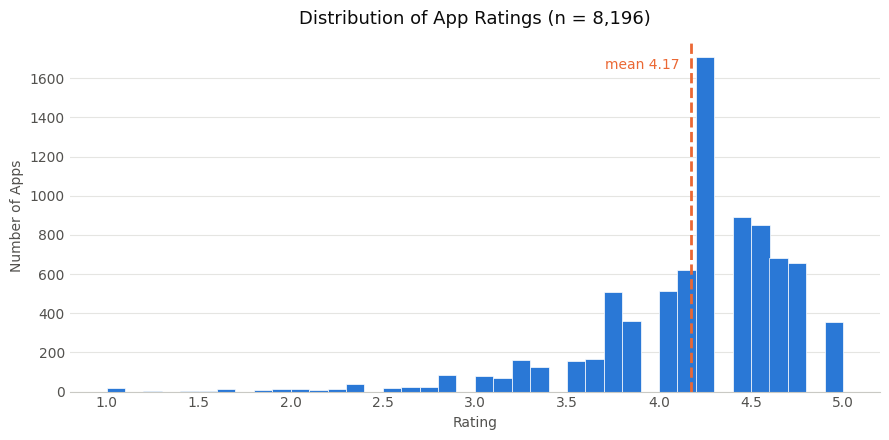

In [102]:
fig, ax = plt.subplots(figsize=(9, 4.5))

ax.hist(clean["Rating"].dropna(), bins=40, color=SERIES, edgecolor="white", linewidth=0.5)
ax.axvline(clean["Rating"].mean(), color=ACCENT, linewidth=2, linestyle="--")
ax.text(clean["Rating"].mean() - 0.06, ax.get_ylim()[1] * 0.92,
        f"mean {clean['Rating'].mean():.2f}", color=ACCENT, ha="right", fontsize=10)

ax.grid(axis="y", color=GRID, linewidth=0.8)
tidy(ax, f"Distribution of App Ratings (n = {clean['Rating'].notna().sum():,})",
     "Rating", "Number of Apps")

plt.tight_layout()
plt.show()

Strongly **left-skewed**: a long thin tail down towards 1.0 and a dense mass between 4.0 and
4.6, peaking at 4.3–4.4. Very few apps sit below 3.0. The dashed line marks the mean, which
sits *below* the peak — the signature of a left-skewed distribution, and the reason the
median (4.3) is the more representative summary.

## 5.2 Which categories rate best and worst?

33 categories is too many for one readable bar chart, so this shows the 10 best and 10 worst
by mean rating. Cutting the middle out is a deliberate choice and is stated in the title —
hiding it silently would misrepresent the spread.

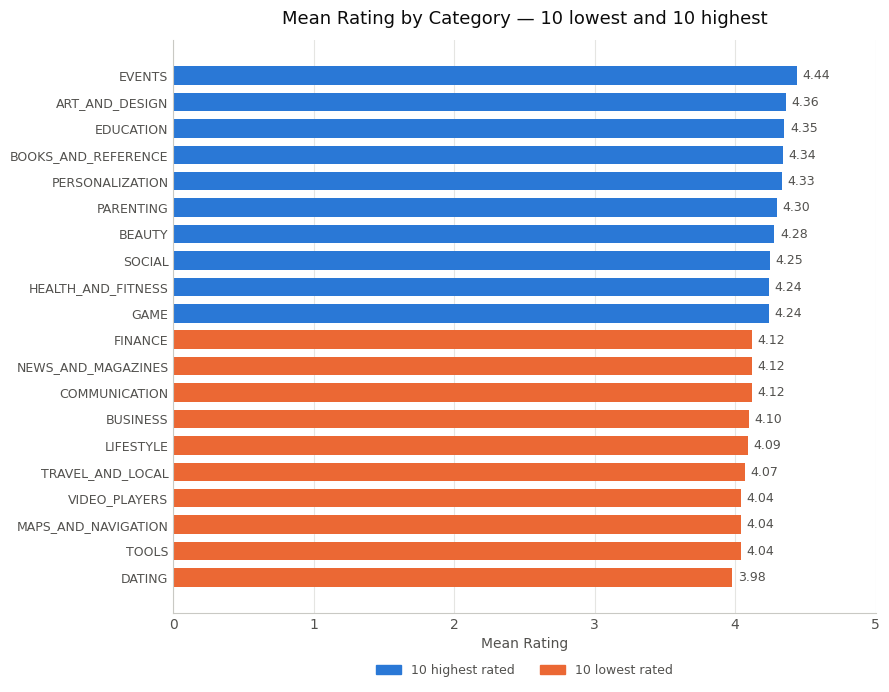

In [103]:
ordered = by_category.sort_values("mean")
extremes = pd.concat([ordered.head(10), ordered.tail(10)])

colors = [ACCENT] * 10 + [SERIES] * 10

fig, ax = plt.subplots(figsize=(9, 7))
bars = ax.barh(extremes.index, extremes["mean"], color=colors, height=0.7)
ax.bar_label(bars, fmt="%.2f", padding=4, color=MUTED, fontsize=9)

ax.set_xlim(0, 5)
ax.grid(axis="x", color=GRID, linewidth=0.8)
tidy(ax, "Mean Rating by Category — 10 lowest and 10 highest",
     "Mean Rating", "", hide_left=False)
ax.tick_params(axis="y", labelsize=9)

# Colour carries meaning here, so it needs a legend rather than a caption.
from matplotlib.patches import Patch
legend = ax.legend(handles=[Patch(color=SERIES, label="10 highest rated"),
                            Patch(color=ACCENT, label="10 lowest rated")],
                   loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=2,
                   frameon=False, fontsize=9)
for text in legend.get_texts():
    text.set_color(MUTED)

plt.tight_layout()
plt.show()

The axis runs the full **0–5** rather than zooming into 3.9–4.5. Zooming would stretch a
0.4-star gap across the whole width and make the categories look wildly different; on the
honest scale the difference is visible but proportionate.

`DATING` is bottom at about 4.0 and `EVENTS` top at about 4.4.

## 5.3 Reviews against installs — the one strong relationship

Both variables span nine orders of magnitude, so a linear scatter would collapse 99 % of the
points into the bottom-left corner. **Log scales on both axes** are the correct form.

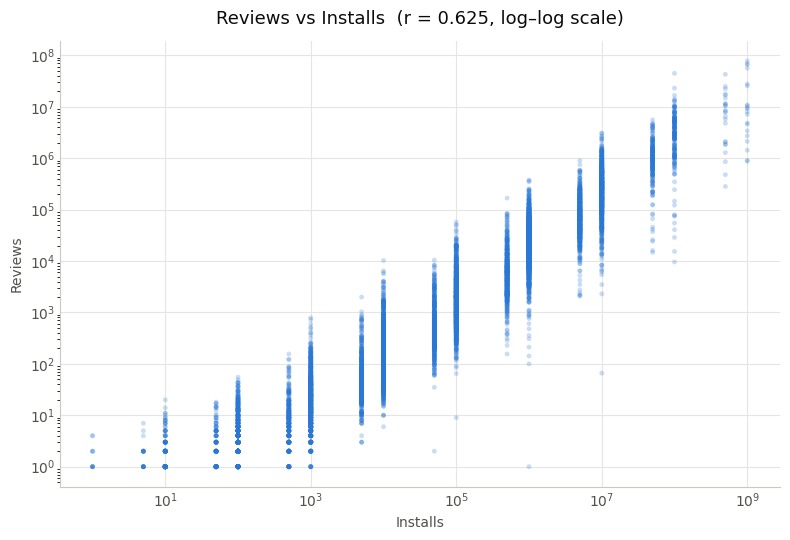

In [104]:
plot_data = clean[(clean["Installs"] > 0) & (clean["Reviews"] > 0)]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(plot_data["Installs"], plot_data["Reviews"],
           s=12, color=SERIES, alpha=0.25, edgecolor="none")

ax.set_xscale("log")
ax.set_yscale("log")
ax.grid(color=GRID, linewidth=0.8)
tidy(ax, f"Reviews vs Installs  (r = {clean['Reviews'].corr(clean['Installs']):.3f}, log–log scale)",
     "Installs", "Reviews", hide_left=False)

plt.tight_layout()
plt.show()

On log–log axes the relationship is obvious: a tight diagonal band running from the bottom
left to the top right, over nine orders of magnitude. The vertical striping is not noise —
it is a consequence of `Installs` being a **bucketed** field, so every app sits on one of
about twenty discrete install values.

The roughly constant width of the band means the *ratio* of reviews to installs stays
fairly stable across the whole range: very roughly one review per 50 installs.

## 5.4 Do free and paid apps rate differently?

Two groups of very unequal size — **8,904 free apps against 754 paid** — so comparing raw
counts would be useless. This compares the **distributions** instead, as percentages within
each group.

The `n` in the legend is smaller than those totals (7,594 and 602) because only rated apps
can appear on a rating chart; the rest were left missing in 3.6.

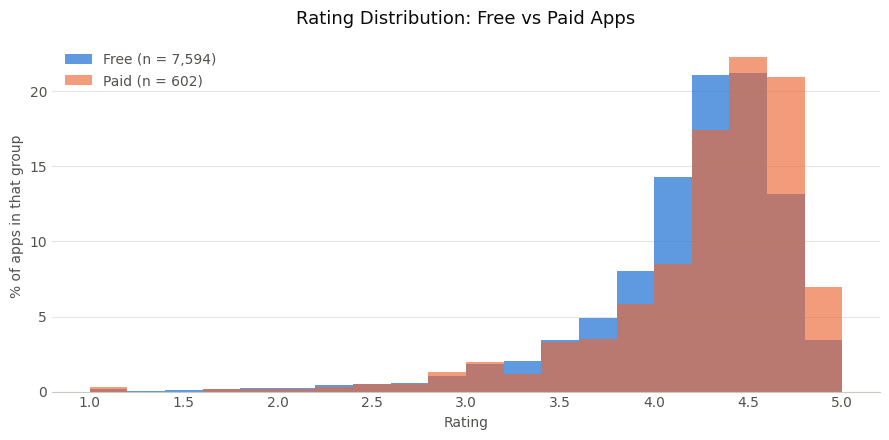

In [105]:
free = clean.loc[clean["Type"] == "Free", "Rating"].dropna()
paid = clean.loc[clean["Type"] == "Paid", "Rating"].dropna()

fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.arange(1, 5.2, 0.2)

ax.hist(free, bins=bins, weights=np.ones(len(free)) / len(free) * 100,
        color=SERIES, alpha=0.75, label=f"Free (n = {len(free):,})")
ax.hist(paid, bins=bins, weights=np.ones(len(paid)) / len(paid) * 100,
        color=ACCENT, alpha=0.65, label=f"Paid (n = {len(paid):,})")

ax.grid(axis="y", color=GRID, linewidth=0.8)
tidy(ax, "Rating Distribution: Free vs Paid Apps", "Rating", "% of apps in that group")
legend = ax.legend(frameon=False, fontsize=10)
for text in legend.get_texts():
    text.set_color(MUTED)

plt.tight_layout()
plt.show()

The two distributions sit almost on top of each other. Paid apps are slightly thinner in the
3.0–4.0 region and slightly fatter above 4.5, which is where their +0.1 average comes from —
but the overlap is so large that app *type* is close to useless as a predictor of rating for
any individual app.

This is why the 0.1-star gap in Question 6 needed the chart: a difference of means can look
decisive in a table and turn out to be two nearly identical distributions.

---
# Module 6 — Build a small report

## 6.1 Category summary table

Named aggregations, chosen to answer "what does each category look like?" — size of the
category, how it rates, how installed it is and what it costs. The median is used for
installs and price because both are extremely skewed.

In [106]:
category_summary = clean.groupby("Category").agg(
    Apps=("App", "count"),
    Rated_Apps=("Rating", "count"),
    Mean_Rating=("Rating", "mean"),
    Median_Installs=("Installs", "median"),
    Median_Size_MB=("Size_MB", "median"),
    Paid_Apps=("Price", lambda s: (s > 0).sum()),
).round(2).sort_values("Apps", ascending=False)

category_summary["Paid_%"] = (
    category_summary["Paid_Apps"] / category_summary["Apps"] * 100).round(1)

category_summary.head(15)

,Apps,Rated_Apps,Mean_Rating,Median_Installs,Median_Size_MB,Paid_Apps,Paid_%
Category,,,,,,,
FAMILY,1878,1653,4.18,50000.0,19.00,185,9.9
GAME,945,898,4.24,1000000.0,37.00,82,8.7
TOOLS,829,720,4.04,50000.0,4.20,78,9.4
BUSINESS,420,263,4.10,1000.0,8.60,12,2.9
MEDICAL,395,290,4.17,1000.0,15.00,82,20.8
PERSONALIZATION,376,298,4.33,10000.0,7.10,81,21.5
PRODUCTIVITY,374,301,4.18,100000.0,6.90,28,7.5
LIFESTYLE,369,301,4.09,10000.0,9.60,19,5.1
FINANCE,345,302,4.12,10000.0,12.00,17,4.9


## 6.2 Overall statistics for the report

In [107]:
report = {
    "Apps analysed": f"{len(clean):,}",
    "Rows removed in cleaning": f"{len(df) - len(clean):,}",
    "Categories": clean["Category"].nunique(),
    "Apps with a rating": f"{clean['Rating'].notna().sum():,}",
    "Mean rating": f"{clean['Rating'].mean():.3f}",
    "Median rating": f"{clean['Rating'].median():.2f}",
    "Free apps": f"{(clean['Type'] == 'Free').sum():,}",
    "Paid apps": f"{(clean['Type'] == 'Paid').sum():,}",
    "Median installs": f"{clean['Installs'].median():,.0f}",
    "Median size (MB)": f"{clean['Size_MB'].median():.1f}",
    "Reviews–Installs correlation": f"{clean['Reviews'].corr(clean['Installs']):.3f}",
}

for key, value in report.items():
    print(f"{key:<30} {value}")

Apps analysed                  9,659
Rows removed in cleaning       1,182
Categories                     33
Apps with a rating             8,196
Mean rating                    4.173
Median rating                  4.30
Free apps                      8,904
Paid apps                      754
Median installs                100,000
Median size (MB)               12.0
Reviews–Installs correlation   0.625


## 6.3 Export the cleaned dataset

In [108]:
clean.to_csv("googleplaystore_cleaned.csv", index=False)
print("Wrote googleplaystore_cleaned.csv", clean.shape)

Wrote googleplaystore_cleaned.csv (9659, 15)


## 6.4 Export the summary

The index (`Category`) is the row label here, so it is kept.

In [109]:
category_summary.to_csv("googleplaystore_category_summary.csv")
print("Wrote googleplaystore_category_summary.csv", category_summary.shape)

Wrote googleplaystore_category_summary.csv (33, 7)


In [110]:
import os

for name in ["googleplaystore_cleaned.csv", "googleplaystore_category_summary.csv"]:
    print(f"{name:<42} {os.path.getsize(name):>9,} bytes")

googleplaystore_cleaned.csv                1,280,018 bytes
googleplaystore_category_summary.csv           1,540 bytes


---
# Challenge exercises

The same ten challenges set in the classwork lab, restated for this dataset. Each one is
written as a plain-English question first.

## Challenge 1 — The five lowest-rated apps

**Question:** which apps have the worst ratings?

A naive `nsmallest(5, "Rating")` returns apps rated 1.0 by a handful of people, which says
more about the sample size than the app. Requiring at least 1,000 reviews gives an answer
that means something — and the unfiltered version is shown alongside to justify the choice.

In [111]:
print("--- Naive: lowest rated, any review count ---")
print(clean.nsmallest(5, "Rating")[["App", "Rating", "Reviews"]].to_string(index=False))

print("\n--- Better: lowest rated among apps with 1,000+ reviews ---")
credible = clean[clean["Reviews"] >= 1000]
print(credible.nsmallest(5, "Rating")[["App", "Category", "Rating", "Reviews"]].to_string(index=False))

--- Naive: lowest rated, any review count ---
                             App  Rating  Reviews
         House party - live chat     1.0        1
               Speech Therapy: F     1.0        1
                   Clarksburg AH     1.0        1
   Truck Driving Test Class 3 BC     1.0        1
BJ Bridge Standard American 2018     1.0        1

--- Better: lowest rated among apps with 1,000+ reviews ---
                           App  Category  Rating  Reviews
                     EB Mobile    FAMILY     1.7     1172
Smart-AC Universal Remote Free    FAMILY     1.8     3270
           AppFinder by AppTap     TOOLS     2.0     2221
               Candy simply-Fi LIFESTYLE     2.1     2390
             PS4 Second Screen    FAMILY     2.4    11773


## Challenge 2 — Average rating: free vs paid

In [112]:
clean.groupby("Type")["Rating"].agg(["count", "mean", "median"]).round(3)

,count,mean,median
Type,,,
Free,7594,4.166,4.3
Paid,602,4.262,4.4


## Challenge 3 — Average rating for each content rating

In [113]:
clean.groupby("Content Rating")["Rating"].agg(["count", "mean"]).round(3).sort_values("mean", ascending=False)

,count,mean
Content Rating,,
Adults only 18+,3,4.300
Everyone 10+,305,4.226
Teen,912,4.226
Everyone,6618,4.166
Mature 17+,357,4.122
Unrated,1,4.100


`Adults only 18+` tops the table at 4.30 and `Unrated` sits bottom at 4.10, but each rests
on a *handful* of apps — 3 and 1 respectively — so neither number means anything at all.

Among the four groups with real volume the spread is genuinely small: `Everyone 10+` and
`Teen` both average 4.23, `Everyone` 4.17 and `Mature 17+` 4.12. Content rating is close to
useless as a predictor of app rating — which is worth stating, because a table sorted by
mean always *looks* like it has found something.

## Challenge 4 — Count, mean and median rating by category

In [114]:
clean.groupby("Category")["Rating"].agg(["count", "mean", "median"]).round(2).sort_values(
    "mean", ascending=False)

,count,mean,median
Category,,,
EVENTS,45,4.44,4.5
ART_AND_DESIGN,59,4.36,4.4
EDUCATION,104,4.35,4.4
BOOKS_AND_REFERENCE,169,4.34,4.5
PERSONALIZATION,298,4.33,4.4
PARENTING,50,4.30,4.4
BEAUTY,42,4.28,4.3
SOCIAL,203,4.25,4.3
HEALTH_AND_FITNESS,244,4.24,4.5


## Challenge 5 — Apps smaller than the median size but rated above the median

**Question:** which small apps punch above their weight?

In [115]:
size_median = clean["Size_MB"].median()
rating_median = clean["Rating"].median()
print(f"Median size: {size_median:.1f} MB | median rating: {rating_median}")

small_and_good = clean[
    (clean["Size_MB"] < size_median) &
    (clean["Rating"] > rating_median)
]

print("Apps matching both conditions:", len(small_and_good), end="\n\n")
small_and_good.nlargest(10, "Installs")[
    ["App", "Category", "Size_MB", "Rating", "Installs"]].to_string(index=False)

Median size: 12.0 MB | median rating: 4.3
Apps matching both conditions: 1331



'                                              App        Category  Size_MB  Rating  Installs\n                               Samsung Calculator           TOOLS      2.5     4.4 100000000\n                   Hola Launcher- Theme,Wallpaper PERSONALIZATION      7.6     4.5 100000000\n                                      Dr. Driving            GAME      9.9     4.5 100000000\n    Parallel Space - Multiple accounts & Two face PERSONALIZATION      7.4     4.6 100000000\n      UC Browser Mini -Tiny Fast Private & Secure   COMMUNICATION      3.3     4.4 100000000\n                 Brightest Flashlight - LED Light           TOOLS      9.1     4.5  50000000\n                      Brightest Flashlight Free ®           TOOLS      3.8     4.7  50000000\n                             Advanced Task Killer    PRODUCTIVITY      1.5     4.4  50000000\n                            Samsung Video Library   VIDEO_PLAYERS      6.1     4.4  50000000\nDU Recorder – Screen Recorder, Video Editor, Live   VIDEO_P

## Challenge 6 — The 10 most frequently repeated app names

**This must be asked of the raw data.** The cleaned DataFrame has exactly one row per app by
construction, so running this on `clean` would correctly return nothing — a good example of
a question that has to be asked before the cleaning that removes its subject.

In [116]:
raw_name_counts = df["App"].value_counts()
print("--- Raw data: most repeated app names ---")
print(raw_name_counts[raw_name_counts > 1].head(10))

print("\n--- Cleaned data: any repeats left? ---")
print("Repeated names:", clean["App"].duplicated().sum())

--- Raw data: most repeated app names ---
App
ROBLOX                                                9
CBS Sports App - Scores, News, Stats & Watch Live     8
ESPN                                                  7
Duolingo: Learn Languages Free                        7
Candy Crush Saga                                      7
8 Ball Pool                                           7
slither.io                                            6
Bubble Shooter                                        6
Zombie Catchers                                       6
Bleacher Report: sports news, scores, & highlights    6
Name: count, dtype: int64

--- Cleaned data: any repeats left? ---
Repeated names: 0


## Challenge 7 — Percentage of apps in each category

In [117]:
category_pct = (clean["Category"].value_counts(normalize=True) * 100).round(2)
category_pct.name = "percent_of_apps"

print("Top 10 categories by share:")
print(category_pct.head(10))
print(f"\nThose 10 account for {category_pct.head(10).sum():.1f}% of all apps.")

Top 10 categories by share:
Category
FAMILY             19.44
GAME                9.78
TOOLS               8.58
BUSINESS            4.35
MEDICAL             4.09
PERSONALIZATION     3.89
PRODUCTIVITY        3.87
LIFESTYLE           3.82
FINANCE             3.57
SPORTS              3.36
Name: percent_of_apps, dtype: float64

Those 10 account for 64.8% of all apps.


## Challenge 8 — Create a `RatingLevel` column

**Rule:** below 3.0 = Poor · 3.0–3.9 = Average · 4.0–4.4 = Good · 4.5+ = Excellent.

`right=False` makes each band include its left edge and exclude its right one, so 4.0 lands
in **Good** rather than in Average. Apps with no rating stay `NaN` — they are unrated, not
poor, and that distinction is the whole point of the 3.6 decision.

In [118]:
clean["RatingLevel"] = pd.cut(
    clean["Rating"],
    bins=[0, 3.0, 4.0, 4.5, 5.01],
    labels=["Poor", "Average", "Good", "Excellent"],
    right=False,
)

print(clean["RatingLevel"].value_counts().sort_index(), end="\n\n")
print("Unrated (left as NaN):", clean["RatingLevel"].isna().sum())
print("Check — bands + unrated =", clean["RatingLevel"].notna().sum() + clean["RatingLevel"].isna().sum(),
      "= total rows", len(clean))

RatingLevel
Poor          278
Average      1631
Good         3737
Excellent    2550
Name: count, dtype: int64

Unrated (left as NaN): 1463
Check — bands + unrated = 9659 = total rows 9659


In [119]:
clean[["App", "Category", "Rating", "RatingLevel"]].head(10)

,App,Category,Rating,RatingLevel
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,Good
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,Excellent
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,Excellent
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,Good
5,Paper flowers instructions,ART_AND_DESIGN,4.4,Good
6,Smoke Effect Photo Maker - Smoke Editor,ART_AND_DESIGN,3.8,Average
7,Infinite Painter,ART_AND_DESIGN,4.1,Good
8,Garden Coloring Book,ART_AND_DESIGN,4.4,Good
9,Kids Paint Free - Drawing Fun,ART_AND_DESIGN,4.7,Excellent
10,Text on Photo - Fonteee,ART_AND_DESIGN,4.4,Good


## Challenge 9 — Chart of median installs by rating level

The classwork's version of this chart plotted the average grade per grade-band, which could
only ever reproduce the bands themselves. This version plots a **different** measurement —
installs — against the rating bands, so the chart can actually tell us something.

Median rather than mean, because installs are extremely skewed; a log scale for the same
reason.

             Apps  Median_Installs  Mean_Rating
RatingLevel                                    
Poor          278           5000.0         2.37
Average      1631         100000.0         3.61
Good         3737        1000000.0         4.23
Excellent    2550         100000.0         4.65



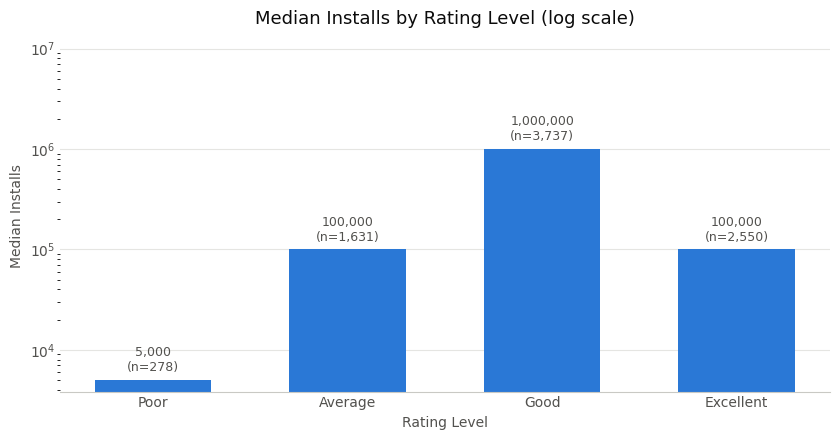

In [120]:
level_stats = clean.groupby("RatingLevel", observed=True).agg(
    Apps=("App", "count"),
    Median_Installs=("Installs", "median"),
    Mean_Rating=("Rating", "mean"),
).round(2)
print(level_stats, end="\n\n")

fig, ax = plt.subplots(figsize=(8.5, 4.5))
bars = ax.bar(level_stats.index.astype(str), level_stats["Median_Installs"],
              color=SERIES, width=0.6)

labels = [f"{int(v):,}\n(n={n:,})" for v, n in zip(level_stats["Median_Installs"], level_stats["Apps"])]
ax.bar_label(bars, labels=labels, padding=4, color=MUTED, fontsize=9)

ax.set_yscale("log")
ax.set_ylim(top=level_stats["Median_Installs"].max() * 12)
ax.grid(axis="y", color=GRID, linewidth=0.8)
tidy(ax, "Median Installs by Rating Level (log scale)", "Rating Level", "Median Installs")

plt.tight_layout()
plt.show()

This is the most interesting chart in the notebook, and **not** because it shows a steady
rise. It does not:

| Rating level | Apps | Median installs |
| :---- | ----: | ----: |
| Poor (<3.0) | 278 | 5,000 |
| Average (3.0–3.9) | 1,631 | 100,000 |
| Good (4.0–4.4) | 3,737 | **1,000,000** |
| Excellent (4.5+) | 2,550 | 100,000 |

Installs climb **200-fold** from Poor to Good — and then fall back **tenfold** at
Excellent. The most-installed apps are not the best-rated ones; they are the *second*-best
rated.

The shape is an **inverted U**, and it is not hard to explain. Apps rated 4.5+ include a
large population of small, niche, enthusiast apps rated by relatively few, very happy
users. The 4.0–4.4 band is where the mass-market apps live — the ones installed by hundreds
of millions of people, who are harder to please and more likely to leave a three-star
review after one bad update.

Now set this against Question 7, where `Rating` vs `Installs` correlated at just **0.040**.
Both results are correct, and together they make the methodological point of this notebook:

> A correlation coefficient measures how well a **straight line** fits. This relationship is
> not a line — it rises and then falls — so no correlation coefficient, on any scale, can
> represent it. Only grouping the data reveals it.

A near-zero correlation does not mean two things are unrelated. It means they are not
related *in the shape the coefficient is able to detect*.

## Challenge 10 — Correlation between the numeric columns

**Question:** which relationships deserve further investigation?

In [121]:
correlation = clean[numeric_cols].corr()
print(correlation.to_string(float_format="{:.3f}".format), end="\n\n")

import itertools
pair_rows = [(a, b, correlation.loc[a, b]) for a, b in itertools.combinations(numeric_cols, 2)]
pair_table = pd.DataFrame(pair_rows, columns=["column_a", "column_b", "correlation"])
pair_table = pair_table.reindex(
    pair_table["correlation"].abs().sort_values(ascending=False).index).reset_index(drop=True)

print(pair_table.to_string(index=False, float_format="{:.3f}".format))

          Rating  Reviews  Installs  Size_MB  Price
Rating     1.000    0.055     0.040    0.063 -0.021
Reviews    0.055    1.000     0.625    0.179 -0.008
Installs   0.040    0.625     1.000    0.134 -0.009
Size_MB    0.063    0.179     0.134    1.000 -0.022
Price     -0.021   -0.008    -0.009   -0.022  1.000

column_a column_b  correlation
 Reviews Installs        0.625
 Reviews  Size_MB        0.179
Installs  Size_MB        0.134
  Rating  Size_MB        0.063
  Rating  Reviews        0.055
  Rating Installs        0.040
 Size_MB    Price       -0.022
  Rating    Price       -0.021
Installs    Price       -0.009
 Reviews    Price       -0.008


### Which relationships deserve further investigation?

**One clearly does, and one deserves it for the opposite reason.**

1. **`Reviews` ↔ `Installs` (0.625)** — strong, and confirmed visually in 5.3 as a tight
   log–log band. Worth investigating as a *ratio*: which apps get far more or far fewer
   reviews than their install count predicts? An app with an unusually high review-to-install
   ratio has an unusually engaged — or unusually angry — user base.

2. **`Rating` ↔ everything (−0.021 to +0.063)** — worth investigating precisely *because*
   Challenge 9 showed the near-zero figure hides a real, large, **non-monotonic** pattern.
   The next step is not a better correlation coefficient; it is to keep working with grouped
   medians, because a rise-then-fall relationship cannot be summarised by a single number.

In [122]:
# The same correlation, computed on the log of installs and reviews.
logged = clean[clean["Installs"] > 0].copy()
logged["log_Installs"] = np.log10(logged["Installs"])
logged["log_Reviews"] = np.log10(logged["Reviews"].replace(0, np.nan))

print("Rating vs Installs      (raw):", round(clean["Rating"].corr(clean["Installs"]), 3))
print("Rating vs log10 Installs     :", round(logged["Rating"].corr(logged["log_Installs"]), 3))
print("Reviews vs Installs     (raw):", round(clean["Reviews"].corr(clean["Installs"]), 3))
print("log Reviews vs log Installs  :", round(logged["log_Reviews"].corr(logged["log_Installs"]), 3))

Rating vs Installs      (raw): 0.04
Rating vs log10 Installs     : 0.084
Reviews vs Installs     (raw): 0.625
log Reviews vs log Installs  : 0.957


Two different lessons come out of this one cell:

* **`Reviews` vs `Installs` goes from 0.625 to 0.957.** Both variables span nine orders of
  magnitude, so the raw coefficient was badly understating an almost perfect relationship.
  Here, changing the scale was the whole fix.
* **`Rating` vs `Installs` goes from 0.040 to only 0.084.** Still near zero. The log scale
  does *not* rescue it — because, as Challenge 9 showed, the relationship rises and then
  falls, and no straight line fits that on any scale.

So the two problems are genuinely different: the first was the wrong **scale**, the second
is the wrong **shape**. Reaching for a log transform fixed one and did nothing for the
other, which is worth remembering before treating any transform as a general remedy.

---
# Findings

### Data quality found (Module 2)

| Check | Result |
| :---- | :---- |
| Rows / columns | 10,841 × 13 |
| Missing cells | 1,487 — 1,474 of them `Rating` (13.6 %) |
| Complete duplicate rows | 483 (4.5 %) |
| Repeated app names | 1,181 rows; 9,660 distinct apps |
| Structurally corrupted rows | 1 (index 10472) — cause of 4 separate symptoms |
| Columns storing numbers as text | 4 — `Reviews`, `Size`, `Installs`, `Price` |
| `Varies with device` sizes | 1,695 (15.6 %) — not missing data |
| Values that looked wrong but were not | 15 zero-install apps, 16 apps priced at $300+ |

### Cleaning decisions (Module 3)

| Problem | Rule applied | Why |
| :---- | :---- | :---- |
| Corrupted row | drop | last column lost to the shift; unrecoverable, 0.009 % of the file |
| Exact duplicate rows | drop | identical in all 13 columns |
| Repeated app names | keep the highest-review scrape | 2.6 proved they are repeated scrapes of one app |
| Text-as-number columns | convert, `errors="coerce"` | no arithmetic is possible otherwise |
| `Varies with device` | → `NaN`, documented | a real answer, but not a number |
| Missing ratings | **left missing** | filling 1,463 would fabricate 15 % of the column |
| Missing versions | left missing | unused, and unguessable |

### What the analysis found (Modules 4–6, Challenges)

* **9,659 apps** survive cleaning, of which **8,196 carry a rating**.
* Mean rating **4.17**, median **4.30**, strongly left-skewed — most apps cluster between
  4.0 and 4.6, and few fall below 3.0.
* **Category matters**: mean ratings run from **3.98** (`DATING`) to **4.44** (`EVENTS`) —
  a real 0.46-star spread, unlike anything in the classwork dataset.
* **Paid apps rate ~0.1 stars above free apps** (4.166 vs 4.262), but 5.4 showed the two
  distributions almost entirely overlap, so type predicts very little for an individual app.
* **`Reviews` and `Installs` are strongly related** — 0.625 raw, and **0.957** on log–log
  axes: nearly a perfect relationship, badly understated by the raw figure.
* **Rating and installs follow an inverted U.** Median installs climb 200× from Poor-rated
  (5,000) to Good-rated apps (1,000,000), then fall tenfold at Excellent (100,000). The
  most-installed apps are the second-best rated, not the best rated.

### The methodological finding

The most transferable result in this notebook is the contradiction between Question 7 and
Challenge 9, and its resolution.

`Rating` vs `Installs` correlates at **0.040** — apparently nothing. Yet grouping the same
two columns shows median installs moving from 5,000 to 1,000,000 and back to 100,000 across
four rating bands. Both numbers are correct, because they measure different things:

> A correlation coefficient measures how well a **straight line** fits. It cannot see a
> relationship that rises and then falls, however large that relationship is.

The obvious remedy fails, which is the useful part. Putting installs on a log scale — the
scale the data genuinely lives on — moves the correlation only from 0.040 to **0.084**,
because the problem was never the scale. Applying the same transform to `Reviews` vs
`Installs` moves it from 0.625 to **0.957**, because there the problem *was* the scale.

Two superficially identical symptoms, two different causes, one remedy that fixes only one
of them. Reporting the 0.040 alone would have been technically accurate and completely
misleading.

### Limits of this analysis

1. **Ratings describe apps with an audience.** 3.7 showed the 1,463 unrated apps are
   overwhelmingly those with no installs and no reviews, so every rating figure here
   describes apps that found users — not the Play Store as a whole.
2. **`Installs` is bucketed, not exact.** An app listed at `100,000+` might have 100,001 or
   999,999 installs. Every install figure is a lower bound, the striping in 5.3 is a direct
   consequence, and the "median installs" figures in Challenge 9 are really "median bucket".
3. **The data is a single snapshot** from 2018. Nothing here supports a claim about change
   over time.
4. **No causal claim is made anywhere.** Paid apps rate higher; that does not mean charging
   for an app improves it.

---
# Data-quality checklist

| # | Check | Where it was done |
| :---- | :---- | :---- |
| 1 | Checked the number of rows and columns | 1.4 — `(10841, 13)` |
| 2 | Inspected data types | 1.6, 1.7 — found 4 text-as-number columns |
| 3 | Counted missing values | 2.1 – 2.3 — 1,487 cells |
| 4 | Checked complete duplicate rows | 2.4 — 483 |
| 5 | Checked whether the key field repeats | 2.5, 2.6 — and investigated *why* |
| 6 | Checked numeric ranges | 2.10 |
| 6b | Distinguished small-sample averages from real effects | Q5 (`<1K` band), C3 |
| 7 | Identified impossible values before replacing them | 2.7 — traced to one broken row |
| 8 | Separated real errors from values that merely look odd | 2.11 |
| 9 | Kept a copy of the raw DataFrame | 3.1 — `df` never modified |
| 10 | Explained every missing-value strategy | 3.2, 3.6, 3.7, 3.8 |
| 11 | Checked whether missingness is random | 3.7 — it is not |
| 12 | Verified the cleaned result | 3.9 + before/after table |
| 13 | Checked the analysis answers a real question | every question stated before its code |
| 14 | Chose the chart form from the data | 5.1 – 5.4 — log scales where the data demanded |
| 15 | Labelled charts, and used honest axis ranges | 5.2 (0–5 axis), 5.3 (log–log) |
| 16 | Stated the limits of the analysis | Findings — four limits recorded |
| 17 | Saved cleaned output separately from raw data | 6.3, 6.4 — raw file never overwritten |

---
# Quick reference — pandas used in this notebook

| Command | Purpose | Used in |
| :---- | :---- | :---- |
| `pd.read_csv()` | Read a CSV into a DataFrame | 1.2 |
| `head()` / `nlargest()` / `nsmallest()` | Preview rows / extremes | 1.3, C1, C5 |
| `shape`, `columns`, `dtypes`, `info()` | Structure and types | 1.4 – 1.7 |
| `describe()` | Numeric summary | 1.8 |
| `isna()` / `notna()` | Find missing values | 2.1, 3.6 |
| `duplicated()` | Detect repeated rows or keys | 2.4, 2.5 |
| `value_counts()` | Frequency table (`normalize=True` for %) | 1.9, C7 |
| `str.replace()` | Strip `$`, `,`, `+` from text numbers | 3.5 |
| `pd.to_numeric(errors="coerce")` | Convert text to number safely | 3.4, 3.5 |
| `map()` | Apply a custom conversion (`Size` → MB) | 3.5 |
| `drop()` / `drop_duplicates(subset=)` | Remove rows / deduplicate on a key | 3.2 – 3.4 |
| `sort_values()` | Order rows | 3.4, Q2 |
| `groupby()` + `agg()` | Grouped statistics, named aggregations | Q4 – Q6, 6.1 |
| `pd.cut()` | Build bands from a continuous column | Q5, C8 |
| `corr()` | Pairwise correlation | Q7, C10 |
| `np.log10()` | Rescale skewed data before correlating | C10 |
| `to_csv()` | Export results | 6.3, 6.4 |
| `ax.hist()` / `barh()` / `scatter()` / `set_xscale("log")` | Charts | 5.1 – 5.4, C9 |